## Bars for probatum

`probatum.Data.from_router` fetches bars through the router into a Data, the one object
every probatum run reads: here Bybit's Bitcoin and Ether perpetuals, hourly over 2024 and
2025, with their funding. Then what a Data holds, and how it is cut, coarsened, joined to
other series and kept.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### The bars

`funding=True` fetches each perpetual's funding events beside its bars. The first run saves
the Data into `bars/`, and later runs load it from there.

In [2]:
PATH = pathlib.Path("../bars/bybit-linear-btcusdt-ethusdt-1h-2024-2025")

if PATH.exists():
    perp = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        perp = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=PATH)

perp

Data(2 instruments, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### What it holds

Each instrument carries its venue, market and assets, and the limits the venue puts on an
order as of the fetch. The fields are numpy arrays on one clock, `(T, N)` with a column for
each instrument.

In [3]:
print(pandas.DataFrame([vars(instrument) for instrument in perp.instruments],
                       index=perp.names))

print(f"\n{perp.interval}, {len(perp):,} bars, closes {perp.closes.shape}, "
      f"times {perp.time.dtype}")
print(f"fingerprint {perp.fingerprint}")

          symbol  market  venue quote contract base  min_notional  max_qty
BTCUSDT  BTCUSDT  linear  bybit  USDT     None  BTC           5.0   1500.0
ETHUSDT  ETHUSDT  linear  bybit  USDT     None  ETH           5.0  10000.0

1h, 17,544 bars, closes (17544, 2), times int64
fingerprint b2:77225f1fad78dab4ed132acabb7bf1a8


### Where it came from

The provenance names the source, the fetch and the warnings the router gave as it paged
back through the history, kept here rather than printed.

In [4]:
{key: value for key, value in perp.provenance.items() if key != "warnings"}

{'source': 'router',
 'venue': 'bybit',
 'interval': '1h',
 'fetched': '2026-11-09 14:37:51',
 'instruments': ['bybit:linear:BTCUSDT', 'bybit:linear:ETHUSDT'],
 'first': '2024-01-01 00:00',
 'last': '2025-12-31 23:00',
 'fingerprint': 'b2:77225f1fad78dab4ed132acabb7bf1a8'}

### The clock and its gaps

`gaps()` lists every place an instrument's bars jump past the interval, an outage on a
market that never closes. `describe()` gives the rows of a run's assumptions that the bars
decide.

In [5]:
print(f"gaps: {perp.gaps()}")

perp.describe()

gaps: []


,name,value,source,grade,direction,cost
0,bars,"1h, 2024-01-01 00:00 to 2025-12-31 23:00, from...","the router, fetched 2026-11-09 14:37:51",venue,None,NaN
1,gaps,none,"the router, fetched 2026-11-09 14:37:51",venue,None,NaN
2,funding events,"4,386","the router, fetched 2026-11-09 14:37:51",venue,None,NaN
3,history,from each instrument's first bar,"the router, fetched 2026-11-09 14:37:51",venue,None,NaN
4,delisting,no delisting time; the router serves none,"the router, fetched 2026-11-09 14:37:51",venue,None,NaN
5,universe,the user's list of 2 instruments,"the router, fetched 2026-11-09 14:37:51",simplified,optimistic,NaN
6,prices,as the venue printed them,"the router, fetched 2026-11-09 14:37:51",venue,None,NaN


### Funding

The events at their own times, a row each, and `funding_rate`, the last rate known at each
bar's end, for features.

            count      mean       min       max
instrument                                     
BTCUSDT      2193  0.000078 -0.000294  0.001128
ETHUSDT      2193  0.000079 -0.001177  0.000972


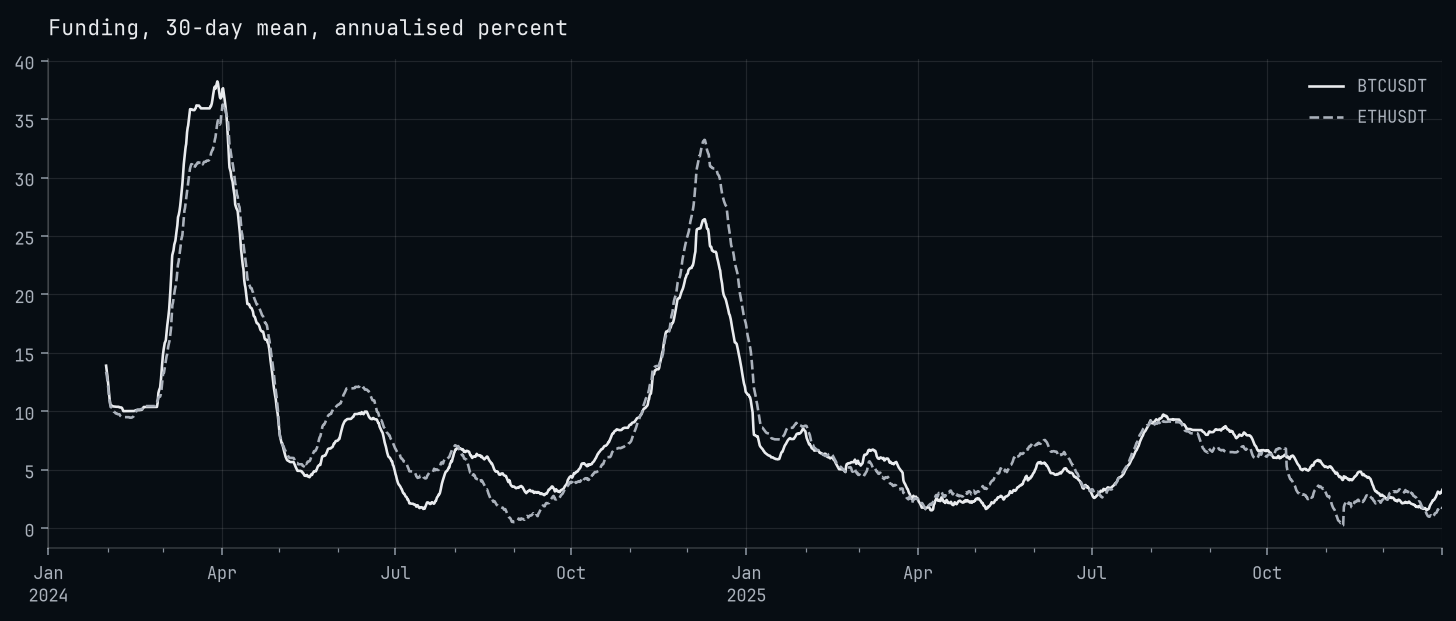

In [6]:
events = pandas.DataFrame(perp.funding)
events["time"] = pandas.to_datetime(events["time"], utc=True)
events["instrument"] = numpy.array(perp.names)[events["instrument"]]

print(events.groupby(by="instrument")["rate"].agg(["count", "mean", "min", "max"]))

axes = pandas.DataFrame(perp.funding_rate * 3 * 365 * 100, columns=perp.names,
                        index=pandas.to_datetime(perp.time, utc=True)).rolling(
    window=24 * 30).mean().plot(title="Funding, 30-day mean, annualised percent", xlabel="")
matplotlib.pyplot.show()

### Slices

A Data slices on time by text, a time or a position, and on instruments by name. Every
slice is a view that keeps the bars before it for warm-up, and has a fingerprint of its
own.

In [7]:
autumn = perp["2025-09":"2025-11"]
train, test = perp.split(when="2025-07-01")
eth = perp["ETHUSDT"]

for name, part in {"autumn": autumn, "train": train, "test": test, "eth": eth}.items():
    print(f"{name:<7} {part!r:<82} {part.fingerprint}")

autumn  Data(2 instruments, 1h, 2184 bars from 2025-09-01 00:00 to 2025-11-30 23:00)       b2:42dae14a6ea98b6b2bd75eb0772d2813
train   Data(2 instruments, 1h, 13128 bars from 2024-01-01 00:00 to 2025-06-30 23:00)      b2:c7e076da991c77c454be09faf1f7911d
test    Data(2 instruments, 1h, 4416 bars from 2025-07-01 00:00 to 2025-12-31 23:00)       b2:a6aae64972b6a72f538b820ceb52d6bd
eth     Data(ETHUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)            b2:b606d56358cb838dbe0bb69904878ec8


### Coarser bars

`resample` builds bars at a multiple of the interval, and `asof` puts what they say back on
the hourly clock from the moment each was known: a day's average lands on the bar that
ends at midnight, never earlier.

In [8]:
daily = perp.resample(interval="1d")
trend = perp.asof(probatum.ta.sma(daily.closes, length=50), when=daily)

around = numpy.arange(start=24 * 59 + 21, stop=24 * 59 + 26)

pandas.DataFrame({"close": perp.closes[around, 0], "daily average as known": trend[around, 0]},
                 index=pandas.to_datetime(perp.time[around], utc=True))

,close,daily average as known
2024-02-29 21:00:00+00:00,61433.9,46289.244
2024-02-29 22:00:00+00:00,61270.3,46289.244
2024-02-29 23:00:00+00:00,61184.1,46579.728
2024-03-01 00:00:00+00:00,61565.1,46579.728
2024-03-01 01:00:00+00:00,61265.4,46579.728


### A series from elsewhere

Binance's funding of the same contract, fetched as a router frame, lands on Bybit's bars by
its own times. Saved beside the bars on the first run, as they are.

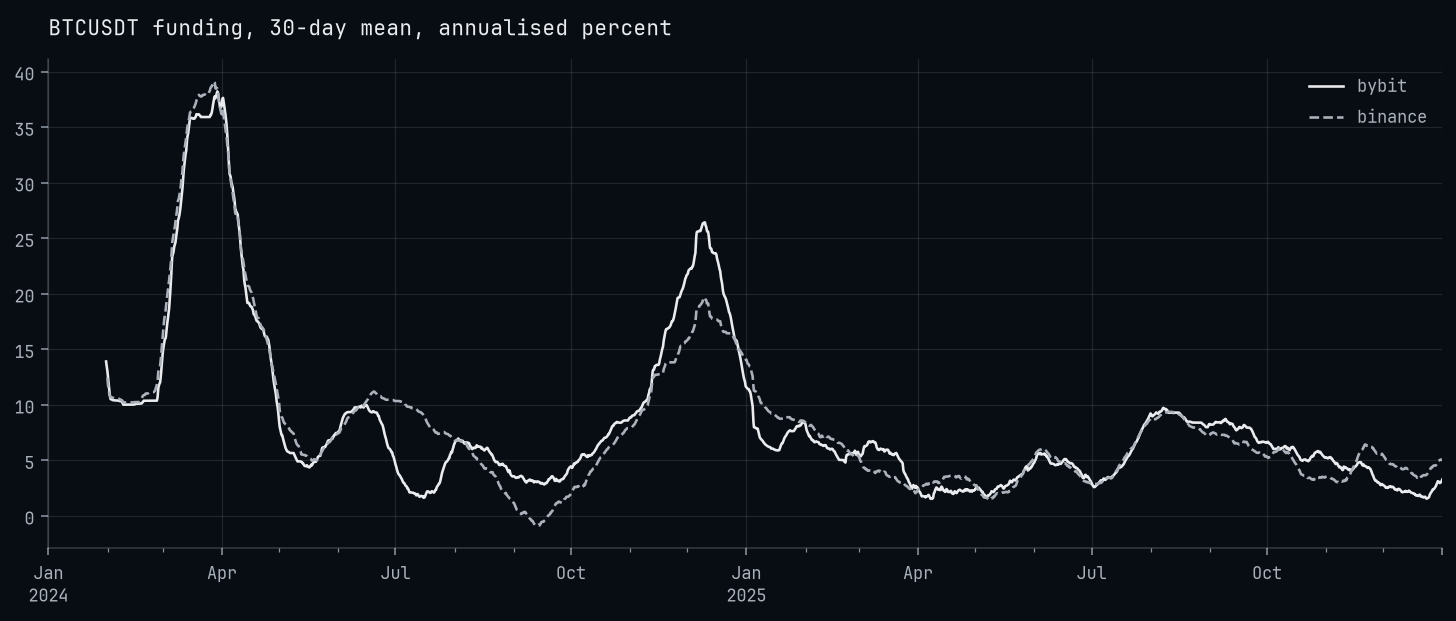

In [9]:
OUTSIDE = pathlib.Path("../bars/binance-linear-btcusdt-funding-2024-2025.parquet")

if OUTSIDE.exists():
    binance = pandas.read_parquet(path=OUTSIDE)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        binance = router.get_funding_rate(exchange="binance", market_type="linear",
                                          symbol="BTCUSDT", limit=2_190,
                                          end=int(pandas.Timestamp("2026-01-01",
                                                                   tz="UTC").timestamp()
                                                  * 1_000) - 1)
    binance.to_parquet(path=OUTSIDE)

elsewhere = perp.asof(binance["funding_per_cycle"])

pandas.DataFrame({"bybit": perp.funding_rate[:, 0], "binance": elsewhere},
                 index=pandas.to_datetime(perp.time, utc=True)).mul(3 * 365 * 100).rolling(
    window=24 * 30).mean().plot(title="BTCUSDT funding, 30-day mean, annualised percent",
                                xlabel="")
matplotlib.pyplot.show()

### Spot and perpetual on one clock

`join` puts two Datas on one clock, here Bybit's spot pair beside the perpetual, each
named by its market where both hold the symbol. Their closes give the basis, the perpetual's
premium over spot.

Data(2 instruments, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00) ('spot:BTCUSDT', 'linear:BTCUSDT')


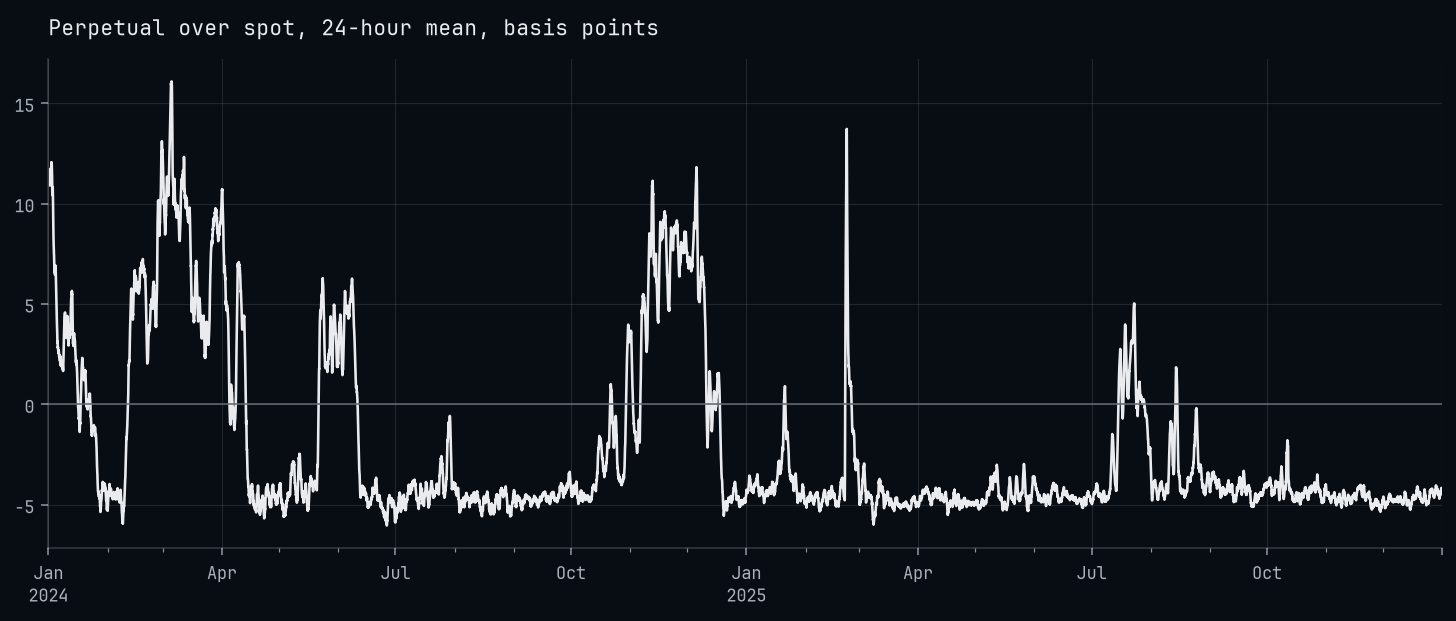

In [10]:
SPOT = pathlib.Path("../bars/bybit-spot-btcusdt-1h-2024-2025")

if SPOT.exists():
    spot = probatum.Data.load(path=SPOT)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        spot = probatum.Data.from_router(router, exchange="bybit", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    spot.save(path=SPOT)

both = spot.join(perp["BTCUSDT"])
print(both, both.names)

basis = (both.closes[:, 1] / both.closes[:, 0] - 1.0) * 10_000

axes = pandas.Series(basis, index=pandas.to_datetime(both.time, utc=True)).rolling(
    window=24).mean().plot(title="Perpetual over spot, 24-hour mean, basis points", xlabel="")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
matplotlib.pyplot.show()

### Kept under its fingerprint

`save` writes three Arrow files any Arrow reader opens, and `load` refuses files that no
longer give the fingerprint they were saved under.

In [11]:
for file in sorted(PATH.iterdir()):
    print(f"{file.name:<18} {file.stat().st_size / 2**20:>6.2f} MB")

again = probatum.Data.load(path=PATH)
print(f"\nloaded {again.fingerprint}, the same: {again.fingerprint == perp.fingerprint}")

bars.arrow           1.74 MB
funding.arrow        0.08 MB
instruments.arrow    0.00 MB

loaded b2:77225f1fad78dab4ed132acabb7bf1a8, the same: True
